Cell 1: Imports & Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import tensorflow as tf
from tensorflow.keras import layers, Model, Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import KLDivergence


# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

sns.set_theme(style="whitegrid")
FEATURE_MATRIX_PATH = "D:\Project\Customer-segmentation\data\cleanCustomerFeature.csv"
##RESULTS_PATH = "D:\Project\Customer-segmentation\results.csv"

<>:22: SyntaxWarning: invalid escape sequence '\P'
<>:23: SyntaxWarning: invalid escape sequence '\P'
<>:22: SyntaxWarning: invalid escape sequence '\P'
<>:23: SyntaxWarning: invalid escape sequence '\P'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_26248\1998080270.py:22: SyntaxWarning: invalid escape sequence '\P'
  FEATURE_MATRIX_PATH = "D:\Project\Customer-segmentation\data\cleanCustomerFeature.csv"
C:\Users\ASUS\AppData\Local\Temp\ipykernel_26248\1998080270.py:23: SyntaxWarning: invalid escape sequence '\P'
  RESULTS_PATH = "D:\Project\Customer-segmentation\results.csv"


Cell 2: Load Data & Standardize Features

In [9]:
# Load feature matrix from Notebook 02
df = pd.read_csv(FEATURE_MATRIX_PATH)

# Select log-transformed behavioral features
log_feature_cols = [col for col in df.columns if col.endswith('_log')]
X_raw = df[log_feature_cols].values

# Standardize features (Mean=0, Std=1) for neural networks & distance-based clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f"Dataset ready: {X_scaled.shape[0]} customers across {X_scaled.shape[1]} log-scaled features.")
print(log_feature_cols)

Dataset ready: 4332 customers across 7 log-scaled features.
['Recency_log', 'Frequency_log', 'Monetary_log', 'TotalQuantity_log', 'TotalItems_log', 'AvgOrderValue_log', 'AvgInterpurchaseDays_log']


Cell 3: Evaluation Metrics Utility Function

In [10]:
def evaluate_clustering(model_name, X_space, labels):
    """Computes Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index."""
    n_clusters = len(np.unique(labels))
    if n_clusters < 2:
        return None
    
    sil = silhouette_score(X_space, labels)
    db = davies_bouldin_score(X_space, labels)
    ch = calinski_harabasz_score(X_space, labels)
    
    return {
        "Model": model_name,
        "Clusters (K)": n_clusters,
        "Silhouette Score (↑)": round(sil, 4),
        "Davies-Bouldin Index (↓)": round(db, 4),
        "Calinski-Harabasz Index (↑)": round(ch, 2)
    }

results_list = []

Cell 4: Model 1 — Traditional Baseline: K-Means on Raw Features

In [11]:
# K-Means directly on standardized features (as cited in literature [3, 5, 10])
for k in [3, 4, 5]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    res = evaluate_clustering(f"Baseline: K-Means (K={k})", X_scaled, labels)
    results_list.append(res)

pd.DataFrame(results_list)

,Model,Clusters (K),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
0,Baseline: K-Means (K=3),3,0.3080,1.1852,2575.33
1,Baseline: K-Means (K=4),4,0.3139,1.1867,2088.46
2,Baseline: K-Means (K=5),5,0.2729,1.2552,1875.55


Cell 5: Model 2 — Linear Dimensionality Reduction: PCA + K-Means

In [12]:
# Linear compression to 3 dimensions before clustering
pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)

for k in [3, 4, 5]:
    kmeans_pca = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_pca = kmeans_pca.fit_predict(X_pca)
    res = evaluate_clustering(f"PCA + K-Means (K={k})", X_pca, labels_pca)
    results_list.append(res)

pd.DataFrame(results_list)

,Model,Clusters (K),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
0,Baseline: K-Means (K=3),3,0.3080,1.1852,2575.33
1,Baseline: K-Means (K=4),4,0.3139,1.1867,2088.46
2,Baseline: K-Means (K=5),5,0.2729,1.2552,1875.55
3,PCA + K-Means (K=3),3,0.3309,1.0649,3256.16
4,PCA + K-Means (K=4),4,0.3422,1.0220,2759.19
5,PCA + K-Means (K=5),5,0.3040,1.0933,2513.68


Cell 6: Model 3 — Autoencoder Latent Embeddings + K-Means (Proposed Framework)

In [13]:
input_dim = X_scaled.shape[1]
latent_dim = 3  # Bottleneck embedding size

# Build Encoder
encoder_input = layers.Input(shape=(input_dim,), name="Encoder_Input")
x = layers.Dense(16, activation="relu")(encoder_input)
x = layers.BatchNormalization()(x)
x = layers.Dense(8, activation="relu")(x)
latent_bottleneck = layers.Dense(latent_dim, activation="linear", name="Latent_Space")(x)

encoder = Model(inputs=encoder_input, outputs=latent_bottleneck, name="Encoder")

# Build Decoder
decoder_input = layers.Input(shape=(latent_dim,), name="Decoder_Input")
y = layers.Dense(8, activation="relu")(decoder_input)
y = layers.Dense(16, activation="relu")(y)
reconstructed_output = layers.Dense(input_dim, activation="linear")(y)

decoder = Model(inputs=decoder_input, outputs=reconstructed_output, name="Decoder")

# Build Full Autoencoder
autoencoder_output = decoder(encoder(encoder_input))
autoencoder = Model(inputs=encoder_input, outputs=autoencoder_output, name="Autoencoder")

autoencoder.compile(optimizer=Adam(learning_rate=0.001), loss="mse")

# Train Autoencoder
history = autoencoder.fit(
    X_scaled, X_scaled,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    verbose=0
)

# Extract Latent Customer Embeddings
embeddings = encoder.predict(X_scaled)

# Perform K-Means on Latent Space
for k in [3, 4, 5]:
    kmeans_ae = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_ae = kmeans_ae.fit_predict(embeddings)
    res = evaluate_clustering(f"Proposed: Autoencoder + K-Means (K={k})", embeddings, labels_ae)
    results_list.append(res)

pd.DataFrame(results_list)

136/136 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Model,Clusters (K),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
0,Baseline: K-Means (K=3),3,0.3080,1.1852,2575.33
1,Baseline: K-Means (K=4),4,0.3139,1.1867,2088.46
2,Baseline: K-Means (K=5),5,0.2729,1.2552,1875.55
3,PCA + K-Means (K=3),3,0.3309,1.0649,3256.16
4,PCA + K-Means (K=4),4,0.3422,1.0220,2759.19
5,PCA + K-Means (K=5),5,0.3040,1.0933,2513.68
6,Proposed: Autoencoder + K-Means (K=3),3,0.5350,0.8881,7015.49
7,Proposed: Autoencoder + K-Means (K=4),4,0.3931,1.0473,6047.41
8,Proposed: Autoencoder + K-Means (K=5),5,0.4004,0.9150,5561.85


Cell 7: Model 4 — Deep Embedded Clustering (DEC) Refinement

In [14]:

class ClusteringLayer(layers.Layer):
    """Custom clustering layer that computes Student's t-distribution kernel."""
    def __init__(self, n_clusters=4, weights=None, alpha=1.0, **kwargs):
        super(ClusteringLayer, self).__init__(**kwargs)
        self.n_clusters = n_clusters
        self.alpha = alpha
        self.initial_weights = weights

    def build(self, input_shape):
        self.clusters = self.add_weight(
            shape=(self.n_clusters, input_shape[1]),
            initializer="glorot_uniform",
            name="cluster_centers"
        )
        if self.initial_weights is not None:
            self.set_weights(self.initial_weights)
        self.built = True

    def call(self, inputs):
        # q_ij = (1 + ||z_i - u_j||^2 / alpha) ^ -((alpha+1)/2)
        q = 1.0 / (1.0 + (tf.reduce_sum(tf.square(tf.expand_dims(inputs, axis=1) - self.clusters), axis=2) / self.alpha))
        q **= (self.alpha + 1.0) / 2.0
        q = tf.transpose(tf.transpose(q) / tf.reduce_sum(q, axis=1))
        return q

# Initialize DEC with K=4
k_opt = 4
kmeans_init = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
init_labels = kmeans_init.fit_predict(embeddings)
cluster_centers_init = kmeans_init.cluster_centers_

# Construct DEC Model
clustering_output = ClusteringLayer(n_clusters=k_opt, weights=[cluster_centers_init], name="DEC_Layer")(encoder.output)
dec_model = Model(inputs=encoder.input, outputs=clustering_output)

# Fix: Use KLDivergence() object directly to avoid version identifier string issues
dec_model.compile(optimizer=Adam(learning_rate=0.0001), loss=KLDivergence())

# DEC Target Distribution Function
def target_distribution(q):
    weight = q ** 2 / q.sum(0)
    return (weight.T / weight.sum(1)).T

# DEC Fine-Tuning Loop
q = dec_model.predict(X_scaled, verbose=0)
p = target_distribution(q)
dec_model.fit(X_scaled, p, epochs=30, batch_size=32, verbose=0)

# Extract DEC Clusters
q_final = dec_model.predict(X_scaled, verbose=0)
dec_labels = q_final.argmax(axis=1)

res = evaluate_clustering(f"Proposed: DEC (K={k_opt})", embeddings, dec_labels)
results_list.append(res)
print("DEC Model Trained & Evaluated Successfully!")

DEC Model Trained & Evaluated Successfully!


Cell 8: Consolidate & Export Benchmark Results Table

In [27]:
# Convert to DataFrame
benchmark_df = pd.DataFrame(results_list)
print("=== LITERATURE MODEL COMPARISON RESULTS ===")
display(benchmark_df)

# Save results for paper / presentation
benchmark_df.to_csv("D:\\Project\\Customer-segmentation\\results.csv", index=False)

=== LITERATURE MODEL COMPARISON RESULTS ===


,Model,Clusters (K),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
0,Baseline: K-Means (K=3),3,0.3080,1.1852,2575.33
1,Baseline: K-Means (K=4),4,0.3139,1.1867,2088.46
2,Baseline: K-Means (K=5),5,0.2729,1.2552,1875.55
3,PCA + K-Means (K=3),3,0.3309,1.0649,3256.16
4,PCA + K-Means (K=4),4,0.3422,1.0220,2759.19
5,PCA + K-Means (K=5),5,0.3040,1.0933,2513.68
6,Proposed: Autoencoder + K-Means (K=3),3,0.5350,0.8881,7015.49
7,Proposed: Autoencoder + K-Means (K=4),4,0.3931,1.0473,6047.41
8,Proposed: Autoencoder + K-Means (K=5),5,0.4004,0.9150,5561.85
9,Proposed: DEC (K=4),4,0.3825,1.0409,5962.19


Cell 9: Assign Final Cluster Labels & Export Profiled Customers

In [20]:
# 1. Explicitly fit K-Means with K=4 on the Autoencoder embeddings
best_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
final_cluster_labels = best_kmeans.fit_predict(embeddings)

# 2. Assign cluster labels back to the DataFrame
df['Cluster'] = final_cluster_labels

# 3. Identify available RFM columns (handles both raw and log-transformed column names safely)
rfm_cols = {}
for col in ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue']:
    if col in df.columns:
        rfm_cols[col] = 'mean'
    elif f'{col}_log' in df.columns:
        rfm_cols[f'{col}_log'] = 'mean'

# 4. Generate Cluster Profile Summary
cluster_summary = df.groupby('Cluster').agg(rfm_cols).round(2)

print("=== SEGMENT PERSONA PROFILE SUMMARY (K=4) ===")
print(cluster_summary)

# 5. Export finalized dataset for Streamlit Dashboard
output_path = "D:\\Project\\Customer-segmentation\\segmented_customers.csv"
df.to_csv(output_path, index=False)
print(f"\nFinal customer segmentations exported successfully to: {output_path}")

=== SEGMENT PERSONA PROFILE SUMMARY (K=4) ===
         Recency  Frequency  Monetary  AvgOrderValue
Cluster                                             
0          66.40       3.46   1048.54          37.12
1         231.08       1.03    173.68          26.30
2         106.28       1.08    407.61          40.59
3          30.90      12.20   7131.90         350.73

Final customer segmentations exported successfully to: D:\Project\Customer-segmentation\segmented_customers.csv


C:\Users\ASUS\AppData\Local\Temp\ipykernel_26248\1638704016.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


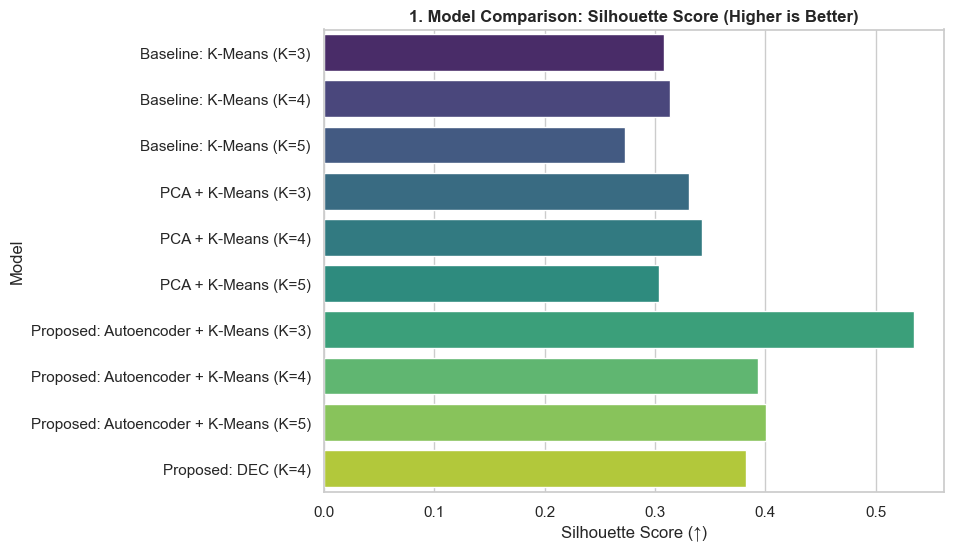

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

# Set up figure grid
fig= plt.figure(figsize=(8, 6))

# ---------------------------------------------------------
# Plot 1: Model Comparison — Silhouette Score
# ---------------------------------------------------------

sns.barplot(
    data=benchmark_df, 
    x="Silhouette Score (↑)", 
    y="Model", 
    palette="viridis"
    
)
plt.title("1. Model Comparison: Silhouette Score (Higher is Better)", fontsize=12, fontweight='bold')


plt.show()



C:\Users\ASUS\AppData\Local\Temp\ipykernel_26248\1709905579.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


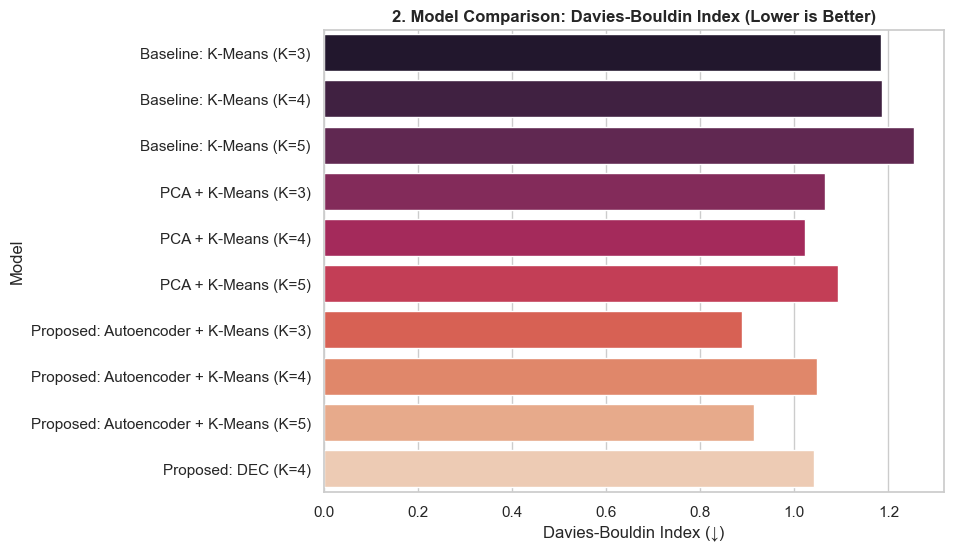

In [43]:
# ---------------------------------------------------------
# Plot 2: Model Comparison — Davies-Bouldin Index
# ---------------------------------------------------------
fig = plt.figure(figsize=(8, 6))
sns.barplot(
    data=benchmark_df, 
    x="Davies-Bouldin Index (↓)", 
    y="Model", 
    palette="rocket", 
    
)
plt.title("2. Model Comparison: Davies-Bouldin Index (Lower is Better)", fontsize=12, fontweight='bold')

plt.show()


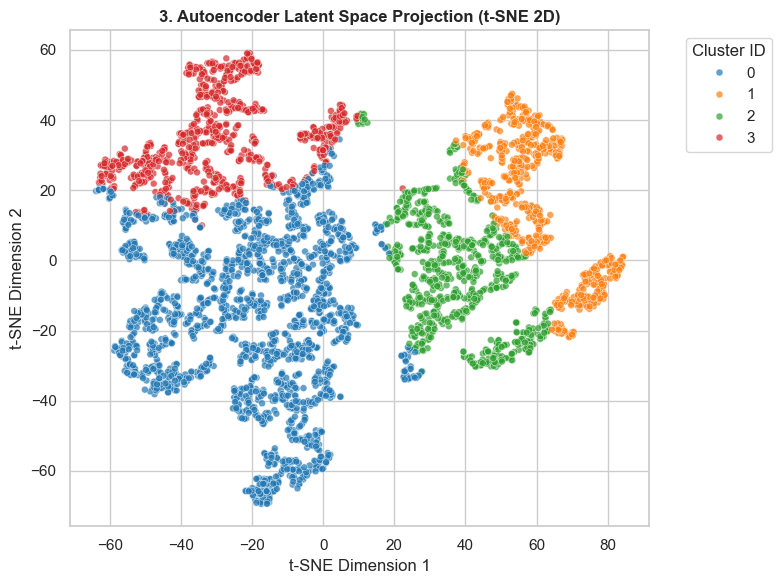

In [47]:
# ---------------------------------------------------------
# Plot 3: 2D t-SNE Projection of Autoencoder Latent Embeddings
# ---------------------------------------------------------
fig = plt.figure(figsize=(8, 6))

# Reduce 3D latent bottleneck embeddings down to 2D using t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
embeddings_2d = tsne.fit_transform(embeddings)

scatter = sns.scatterplot(
    x=embeddings_2d[:, 0], 
    y=embeddings_2d[:, 1], 
    hue=final_cluster_labels, 
    palette="tab10", 
    alpha=0.7, 
    s=25
)
plt.title("3. Autoencoder Latent Space Projection (t-SNE 2D)", fontsize=12, fontweight='bold')
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.legend(title="Cluster ID", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


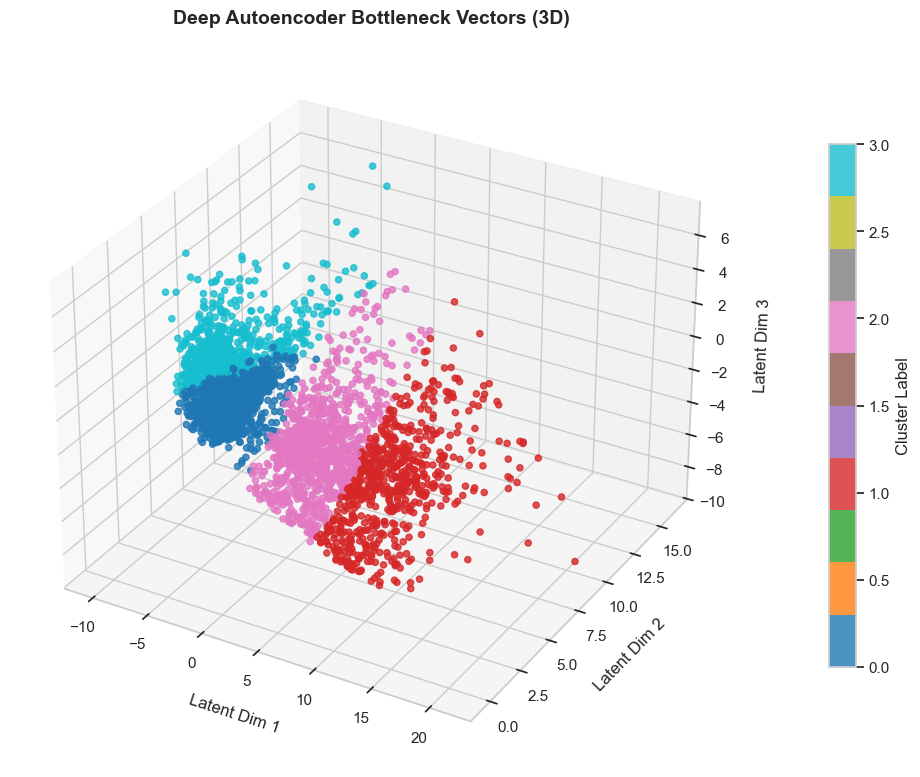

In [48]:
# ---------------------------------------------------------
# Plot 4: 3D Latent Bottleneck Cluster Visualization
# ---------------------------------------------------------
#Set up a standalone 3D figure
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot 3D Latent Bottleneck Clusters
scatter = ax.scatter(
    embeddings[:, 0], 
    embeddings[:, 1], 
    embeddings[:, 2], 
    c=final_cluster_labels, 
    cmap="tab10", 
    alpha=0.8, 
    s=20
)

# Axis labels and title
ax.set_title("Deep Autoencoder Bottleneck Vectors (3D)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Latent Dim 1", labelpad=10)
ax.set_ylabel("Latent Dim 2", labelpad=10)
ax.set_zlabel("Latent Dim 3", labelpad=10)

# Add colorbar for cluster identification
cbar = fig.colorbar(scatter, ax=ax, pad=0.1, shrink=0.7)
cbar.set_label("Cluster Label")

plt.tight_layout()
# plt.savefig("../data/processed/3d_bottleneck_clusters.png", dpi=300)
plt.show()